# Themes

One drawing in five built-in themes, a variant of a theme, a theme read from a file, and a theme made
the default for a block of code.

Run it as ``python 14_themes.py`` or open ``14_themes.ipynb`` to see each step.

In [1]:
import svgwriter as svg

Elements take a *role* (`as_role("box")`) instead of colors. The document's theme turns each role
into one CSS rule, so the SVG holds a small `<style>` sheet and class names, and stays restylable.
Builder shapes carry roles already: `star` is a `shape`, `arrow` an `arrow.line`, `dot` a `dot`.

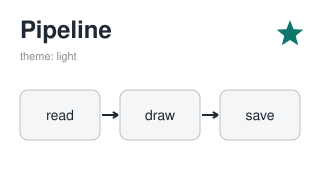

In [2]:
WIDTH, HEIGHT = 320, 180


def card(theme: svg.Theme | str = "light") -> svg.Document:
    """A small diagram drawn only with roles."""
    doc = svg.Document(WIDTH, HEIGHT, theme=theme)
    doc.rect(0, 0, WIDTH, HEIGHT, rx=12).as_role("background")
    doc.text("Pipeline", x=20, y=38).as_role("title")
    doc.text(f"theme: {doc.theme.name}", x=20, y=60).as_role("caption")
    for index, label in enumerate(("read", "draw", "save")):
        x = 20 + index * 100
        doc.rect(x, 90, 80, 50, rx=8).as_role("box")
        doc.text(label, x=x + 40, y=120, text_anchor="middle").as_role("text")
        if index:
            doc += svg.builder.arrow(x - 18, 115, x - 2, 115, head=6)
    doc += svg.builder.star(290, 34, 14, 6)
    return doc


card()

The same function in every built-in theme: `dark`, `paper`, `print` (high contrast for papers) and `mono`.

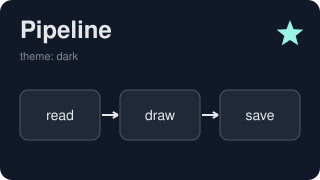

In [3]:
card("dark")

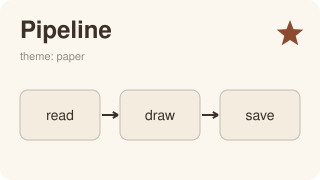

In [4]:
card("paper")

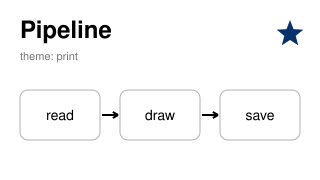

In [5]:
card("print")

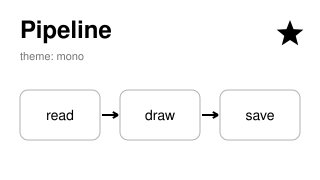

In [6]:
card("mono")

`replace` builds a variant: palette entries, fonts and role properties merge into the base theme.
Palette entries may be functions of the palette, so derived colors follow their sources.

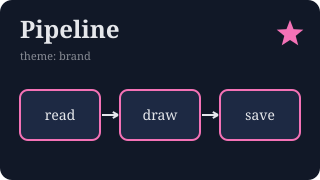

In [7]:
brand = svg.Theme.get("dark").replace(
    name="brand",
    palette={"primary": "#f472b6", "surface": lambda p: p.background.lighten(0.08)},
    fonts={"family": "Georgia, serif"},
    roles={"box": {"stroke": "{palette.primary}", "stroke-width": 2}},
)
card(brand)

Themes are saved and read as TOML. Values are literals or `{palette.name}` / `{fonts.sizes.name}`
references, and a file extends a registered theme.

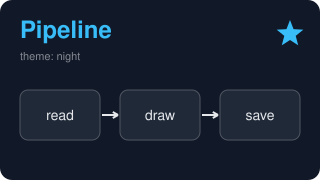

In [8]:
NIGHT = """
name = "night"
extends = "dark"

[palette]
primary = "#38bdf8"
accent = "{palette.primary}"

[roles.title]
fill = "{palette.primary}"
"""
night = svg.Theme.from_toml(NIGHT)
card(night)

`with theme:` makes a theme the default for documents created inside the block.

In [9]:
with svg.Theme.get("paper"):
    default = svg.Document(120, 40)
default.theme.name

'paper'

The themed drawing exports like any other: the renderers resolve the style sheet.

In [10]:
if __name__ == "__main__":
    brand.save("brand.toml")
    for name in ("light", "dark", "paper", "print", "mono"):
        card(name).save(f"themes-{name}.svg")
    card(brand).save("themes-brand.png", scale=2)